## Muhammet Sait Bozdemir
## 2584738
## CENG-501 Homework 3

Hocam, unfortunately, due to the intensity of my finals and graduation project, I couldn't complete the assignment on time. I believe I designed the model's architecture correctly, but I didn't have enough time to optimize it, so I'll upload it as is.

In [1]:
import torchvision.datasets as datasets
import torchvision.transforms as transforms
import torch
import torch.nn as nn
import numpy as np
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F
import matplotlib.pyplot as plt
import timm
from transformers import DistilBertTokenizer, DistilBertModel
import tqdm

train_data = datasets.MNIST(root="./data", train=True, download=True, transform=transforms.ToTensor())
test_data = datasets.MNIST(root="./data", train=False, download=True, transform=transforms.ToTensor())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f'Using device: {device}')



Using device: cuda


## Generating Concatanated and Captioned Dataset

In [2]:
def convertToCaption(label1:int, label2:int, label3:int):
    tens = {0:"", 2:"twenty", 3:"thirty", 4:"forty", 5:"fifty", 6:"sixty", 7:"seventy", 8:"eighty", 9:"ninety"}
    units = {0:"", 1:"one", 2:"two", 3:"three", 4:"four", 5:"five", 6:"six", 7:"seven", 8:"eight", 9:"nine"}
    teens = {0:"ten", 1:"eleven", 2:"twelve", 3:"thirteen", 4:"fourteen", 5:"fifteen", 6:"sixteen", 7:"seventeen", 8:"eighteen", 9:"nineteen"}

    if label1 != 0:
        hundred_part = units[label1] + " hundred"
        if label2 == 1:
            caption = hundred_part + " " + teens[label3]
        else:
            caption = hundred_part + " " + tens[label2] + " " + units[label3]
    else:
        if label2 == 1:
            caption = teens[label3]
        else:
            caption = tens[label2] + " " + units[label3]

    if label1 == 0 and label2 == 0 and label3 == 0:
        caption = "zero"

    # clean up extra spaces
    caption = caption.replace("  ", " ")
    return caption.strip()


class MNIST_Concatted(Dataset):
    def __init__(self, mnist_dataset, num_samples=50000, exclude_123=False, seed=42):
        super().__init__()
        self.mnist_dataset = mnist_dataset
        self.transform = transforms.Compose([
            transforms.ToPILImage(),
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Lambda(lambda x: x.repeat(3, 1, 1))
        ])
        self.exclude_123 = exclude_123
        torch.manual_seed(seed)
        self.indices = self._generateIndices(num_samples)

    def _generateIndices(self, num_samples):
        dataset_size = len(self.mnist_dataset)
        indices = []

        while len(indices) < num_samples:
            idx1 = torch.randint(0, dataset_size, (1,))
            idx2 = torch.randint(0, dataset_size, (1,))
            idx3 = torch.randint(0, dataset_size, (1,))

            _, label1 = self.mnist_dataset[idx1.item()]
            _, label2 = self.mnist_dataset[idx2.item()]
            _, label3 = self.mnist_dataset[idx3.item()]

            # Skip if excluding 1, 2, 3
            if self.exclude_123 and (label1 == 1 and label2 == 1 and label3 == 1):
                continue

            indices.append((idx1, idx2, idx3, label1, label2, label3))

        return indices

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        idx1, idx2, idx3, label1, label2, label3 = self.indices[idx]

        img1, _ = self.mnist_dataset[idx1.item()]
        img2, _ = self.mnist_dataset[idx2.item()]
        img3, _ = self.mnist_dataset[idx3.item()]

        # concatanate
        concat_image = torch.cat((img1, img2, img3), dim=2)

        # zero padding
        paddings = torch.zeros(1, 28, 84)
        concat_image = torch.cat([paddings, concat_image, paddings], dim=1)

        # resizeing to 224x224 and converting to 3 channels
        concat_image = self.transform(concat_image)

        new_label = label1*100 + label2*10 + label3
        new_caption = convertToCaption(label1, label2, label3)

        return concat_image, new_label, new_caption

class MNIST_Concatted_123(Dataset):
    def __init__(self, mnist_dataset, num_samples=100, seed=42):
        super().__init__()
        self.mnist_dataset = mnist_dataset
        self.seed = seed
        self.num_samples = num_samples
        self.transform = transforms.Compose([
            transforms.ToPILImage(),
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Lambda(lambda x: x.repeat(3, 1, 1))
        ])
        torch.manual_seed(seed)
        self.indices = self._generateIndices()

    def _generateIndices(self):
        self.ones = [i for i, (_, label) in enumerate(self.mnist_dataset) if label == 1]
        self.twos = [i for i, (_, label) in enumerate(self.mnist_dataset) if label == 2]
        self.threes = [i for i, (_, label) in enumerate(self.mnist_dataset) if label == 3]

        np.random.seed(self.seed)
        indices = []
        while len(indices) < self.num_samples:
            idx1 = np.random.choice(self.ones)
            idx2 = np.random.choice(self.twos)
            idx3 = np.random.choice(self.threes)
            indices.append((idx1, idx2, idx3))
        return indices

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        idx1, idx2, idx3 = self.indices[index]

        img1, label1 = self.mnist_dataset[idx1]
        img2, label2 = self.mnist_dataset[idx2]
        img3, label3 = self.mnist_dataset[idx3]

        # concatanate
        concat_image = torch.cat((img1, img2, img3), dim=2)

        # zero padding
        paddings = torch.zeros(1, 28, 84)
        concat_image = torch.cat([paddings, concat_image, paddings], dim=1)

        # resizeing to 224x224 and converting to 3 channels
        concat_image = self.transform(concat_image)

        new_label = label1*100 + label2*10 + label3
        new_caption = convertToCaption(label1, label2, label3)

        return concat_image, new_label, new_caption

concat_test_data = MNIST_Concatted(test_data, num_samples=len(test_data))
concat_train_data = MNIST_Concatted(train_data, num_samples=len(train_data), exclude_123=True)
test_123_dataset = MNIST_Concatted_123(test_data, num_samples=100)

## Some Examples

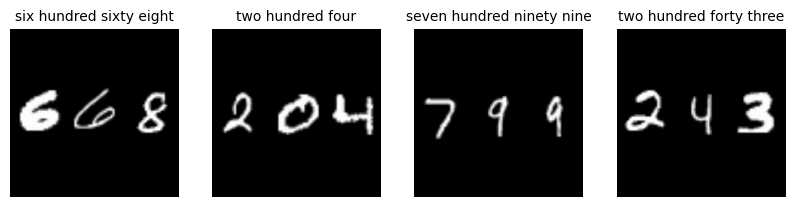

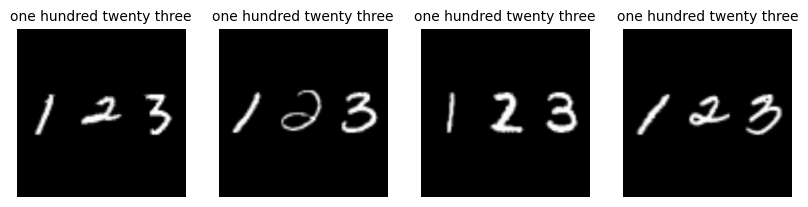

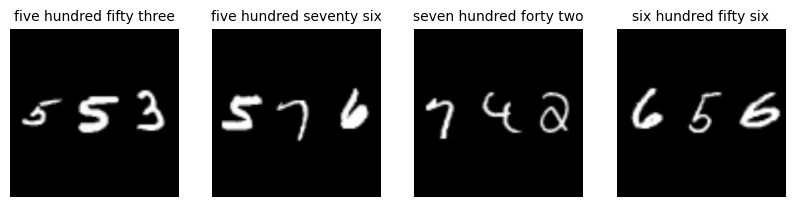

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(10, 5))
for i in range(4):
    ax = axes[i]
    img, label, caption = concat_train_data[i]
    ax.imshow(img.permute(1, 2, 0).numpy(), cmap="gray")
    ax.set_title(f"{caption}", fontdict={'fontsize': 10})
    ax.axis("off")
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(10, 5))
for i in range(4):
    ax = axes[i]
    img, label, caption = test_123_dataset[i]
    ax.imshow(img.permute(1, 2, 0).numpy(), cmap="gray")
    ax.set_title(f"{caption}", fontdict={'fontsize': 10})
    ax.axis("off")
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(10, 5))
for i in range(4):
    ax = axes[i]
    img, label, caption = concat_test_data[i]
    ax.imshow(img.permute(1, 2, 0).numpy(), cmap="gray")
    ax.set_title(f"{caption}", fontdict={'fontsize': 10})
    ax.axis("off")
plt.show()

## Text and Vision Encoders

In [4]:
# vision encoder
vision_encoder = timm.create_model("vit_tiny_patch16_224", pretrained=True, num_classes=0)
vision_encoder.to(device)
vision_encoder.eval()

# text encoder
tokenizer = DistilBertTokenizer.from_pretrained("distilbert-base-uncased")
text_encoder = DistilBertModel.from_pretrained("distilbert-base-uncased")
text_encoder = text_encoder.to(device)
text_encoder.eval()

# Freeze the encoders here to save memory
for param in text_encoder.parameters():
    param.requires_grad = False

for param in vision_encoder.parameters():
    param.requires_grad = False

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(
'(ReadTimeoutError("HTTPSConnectionPool(host='huggingface.co', port=443): Read timed out. (read timeout=10)"), '(Request ID: 6804430b-b571-40f3-ada3-c8a845b835f0)')' thrown while requesting HEAD https://huggingface.co/timm/vit_tiny_patch16_224.augreg_in21k_ft_in1k/resolve/main/model.safetensors
Retrying in 1s [Retry 1/5].


## Projection Layers

In [5]:
class ProjectionHead(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.projection = nn.Linear(input_dim, output_dim)

    def forward(self, x):
        return self.projection(x)

vision_projection = ProjectionHead(input_dim=192, output_dim=128).to(device)
text_projection = ProjectionHead(input_dim=768, output_dim=128).to(device)

## SigLIP Loss

In [6]:
class SigLIPLoss(nn.Module):
    def __init__(self, t_prime=1.0, bias=0.0):
        super().__init__()
        # learnable parameters temperature and bias
        self.t = nn.Parameter(torch.tensor(t_prime))
        self.bias = nn.Parameter(torch.tensor(bias))

    def forward(self, image_emb: torch.Tensor, text_emb: torch.Tensor):
        # batchsize
        B = image_emb.shape[0]
        # L2 normalization as shown in the paper
        imgage_emb_norm = F.normalize(image_emb, p=2, dim=1)
        text_emb_norm = F.normalize(text_emb, p=2, dim=1)

        logits = imgage_emb_norm @ text_emb_norm.t() * self.t.exp() + self.bias
        labels = 2 * torch.eye(B).to(device) - 1

        loss = -F.logsigmoid(labels * logits).sum() / B

        return loss

siglip_loss = SigLIPLoss(t_prime=np.log(1.0), bias=-10.0).to(device)

## Data Loading

In [7]:
def collate_fn(batch):
    images = torch.stack([item[0] for item in batch])
    labels = [item[1] for item in batch]
    captions = [item[2] for item in batch]
    return images, labels, captions

batch_size = 128
train_loader = DataLoader(concat_train_data, batch_size=batch_size, shuffle=True, collate_fn=collate_fn)
test_123_loader = DataLoader(test_123_dataset, batch_size=32, collate_fn=collate_fn)
test_loader = DataLoader(concat_test_data, batch_size=batch_size, collate_fn=collate_fn)

## Training

In [8]:
def train_model(epochs, train_loader, vision_encoder, text_encoder, tokenizer, vision_projection, text_projection, siglip_loss, optimizer):
    vision_projection.train()
    text_projection.train()

    losses = []
    for epoch in range(epochs):
        epoch_loss = 0.0
        num_batches = 0
        print(f"Starting epoch {epoch+1}/{epochs}...")
        for batch_idx, (images, labels, captions) in enumerate(train_loader):
            images = images.to(device)
            captions = list(captions)

            # tokenize captions
            tokens = tokenizer(captions, return_tensors="pt", padding=True, truncation=True)
            tokens = {key: val.to(device) for key, val in tokens.items()}

            # freeze encoders here to save computation
            with torch.no_grad():
                text_embeddings = text_encoder(**tokens)
                text_embeddings = text_embeddings.last_hidden_state[:, 0, :] # [CLS] token
                vision_embeddings = vision_encoder(images)

            vision_projections = vision_projection(vision_embeddings)
            text_projections = text_projection(text_embeddings)

            loss = siglip_loss(vision_projections, text_projections)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()
            num_batches += 1

        losses.append(epoch_loss / num_batches)
        print(f"Epoch {epoch+1}/{epochs}, Loss: {losses[-1]:.4f}")

    return losses

trainable_params = list(vision_projection.parameters()) + list(text_projection.parameters()) + list(siglip_loss.parameters())

# hyperparameters
#for epoch in [10]:
#    for lr in [0.01, 0.001, 0.0001]:
#        for weight_decay in [0.0, 1e-4, 1e-3]:
#            optimizer = torch.optim.AdamW(trainable_params, lr=lr, weight_decay=weight_decay)
#            scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epoch)
#
#            train_losses = train_model(epoch, train_loader, vision_encoder, text_encoder, tokenizer, vision_projection, text_projection, siglip_loss, optimizer,scheduler)

epoch = 10
lr = 0.01
optimizer = torch.optim.AdamW(trainable_params, lr=lr)

train_losses = train_model(epoch, train_loader, vision_encoder, text_encoder, tokenizer, vision_projection, text_projection, siglip_loss, optimizer)

Starting epoch 1/10...
Epoch 1/10, Loss: 6.2029
Starting epoch 2/10...
Epoch 2/10, Loss: 4.0795
Starting epoch 3/10...
Epoch 3/10, Loss: 3.4343
Starting epoch 4/10...
Epoch 4/10, Loss: 3.2408
Starting epoch 5/10...
Epoch 5/10, Loss: 3.1028
Starting epoch 6/10...
Epoch 6/10, Loss: 3.0198
Starting epoch 7/10...
Epoch 7/10, Loss: 2.9443
Starting epoch 8/10...
Epoch 8/10, Loss: 2.8834
Starting epoch 9/10...
Epoch 9/10, Loss: 2.8288
Starting epoch 10/10...
Epoch 10/10, Loss: 2.8206


## Plotting the Loss curve

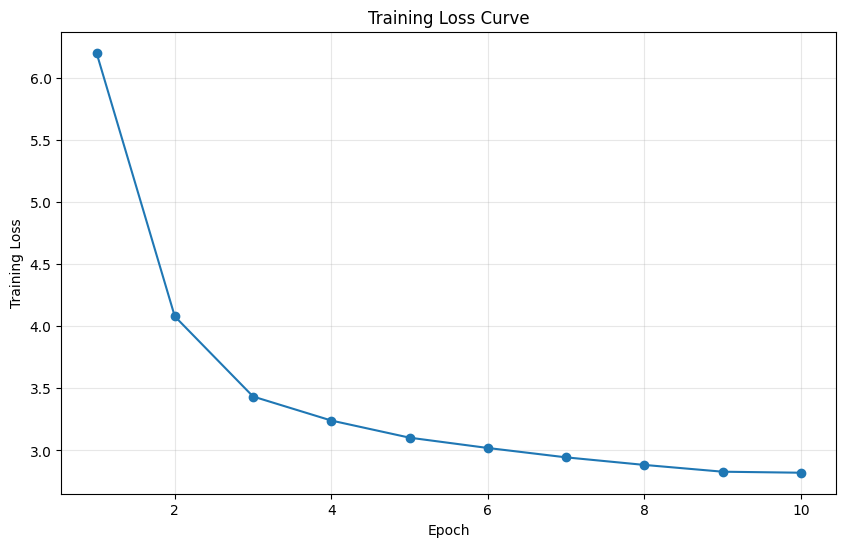

In [10]:
plt.figure(figsize=(10, 6))
plt.plot(range(1, epoch + 1), train_losses, marker='o')
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss Curve")
plt.grid(True, alpha=0.3)
plt.show()

## Evaluate model

In [11]:
# Generating all captions for numbers 0-999
captions_1000 = []
for num in range(1000):
    label1 = num // 100
    label2 = (num % 100) // 10
    label3 = num % 10
    caption = convertToCaption(label1, label2, label3)
    captions_1000.append(caption)

# embeddings for all captions
caption_embeddings = []
text_encoder.eval()
eval_batch_size = 100

with torch.no_grad():
    for i in range(0, len(captions_1000), eval_batch_size):
        batch_captions = captions_1000[i:i+eval_batch_size]
        tokens = tokenizer(batch_captions, return_tensors="pt", padding=True, truncation=True).to(device)
        tokens = {key: val.to(device) for key, val in tokens.items()}
        text_emb = text_encoder(**tokens)
        text_emb = text_emb.last_hidden_state[:, 0, :]  # [CLS] token
        text_proj = text_projection(text_emb)
        caption_embeddings.append(F.normalize(text_proj, p=2, dim=1))

caption_embeddings = torch.cat(caption_embeddings, dim=0)

def evaluate_examples(image, vision_encoder, vision_projection, caption_embeddings, top_k):
    vision_projection.eval()

    with torch.no_grad():
        # ensuring there is a bath dimension
        if len(image.shape) == 3:
            image = image.unsqueeze(0)
        image = image.to(device)

        vision_emb = vision_encoder(image)
        vision_proj = vision_projection(vision_emb)
        vision_proj = F.normalize(vision_proj, p=2, dim=1)

        # cosine similarity
        similarities = vision_proj @ caption_embeddings.t()
        similarities = similarities.squeeze(0)
        top_k_values, top_k_indices = torch.topk(similarities, top_k)

    return top_k_indices.cpu().numpy(), top_k_values.cpu().numpy()

def topKAccuracies(data_loader, vision_encoder, vision_projection, caption_embeddings):

    vision_projection.eval()
    correct_top5 = 0
    correct_top1 = 0
    total = 0

    with torch.no_grad():
        for images, labels, captions in tqdm.tqdm(data_loader):
            images = images.to(device)

            vision_embeddings = vision_encoder(images)
            vision_projections = vision_projection(vision_embeddings)
            vision_projections = F.normalize(vision_projections, p=2, dim=1)


            similarities = vision_projections @ caption_embeddings.t()

            top_5_pred = torch.topk(similarities, 5, dim=1).indices
            top_1_pred = top_5_pred[:,0]

            # converting int labels to tensor
            labels = torch.tensor(labels, device=device)

            correct_top1 += (top_1_pred == labels).sum().item()
            for i in range(labels.size(0)):
                if labels[i] in top_5_pred[i]:
                    correct_top5 += 1

            total += len(labels)

    top1_acc = correct_top1 / total
    top5_acc = correct_top5 / total

    return top1_acc, top5_acc


## Example Evaluations with top-1 Accuracy

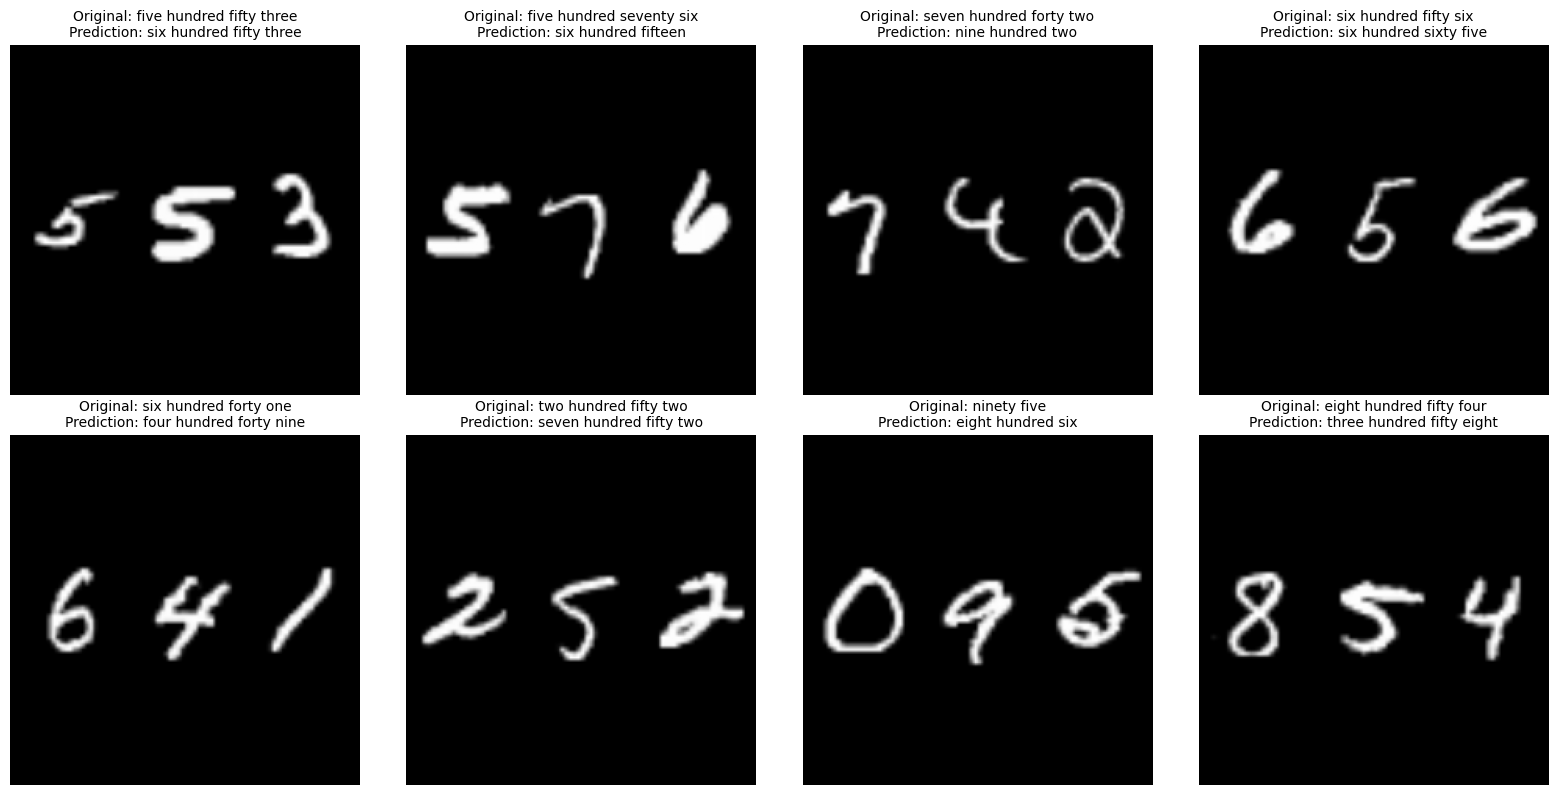

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for i in range(8):
    img, label, caption = concat_test_data[i]
    top_k_indices, top_k_values = evaluate_examples(img, vision_encoder, vision_projection, caption_embeddings, top_k=1)

    ax = axes[i // 4, i % 4]
    ax.imshow(img.permute(1, 2, 0).numpy())

    predicted_caption = captions_1000[top_k_indices[0]]
    ax.set_title(f"Original: {caption}\nPrediction: {predicted_caption}", fontdict={'fontsize': 10})
    ax.axis('off')

plt.tight_layout()
plt.show()

## top-1 and top-5 Accuracies on Test Set

In [13]:
top1_acc, top5_acc = topKAccuracies(test_loader, vision_encoder, vision_projection, caption_embeddings)
print(f"Top-1 Accuracy: {top1_acc*100:.2f}%")
print(f"Top-5 Accuracy: {top5_acc*100:.2f}%")

100%|██████████| 79/79 [00:26<00:00,  3.01it/s]

Top-1 Accuracy: 23.04%
Top-5 Accuracy: 54.02%


## top-1 and top-5 Accuracies on "123" Dataset

In [14]:
top_acc_123, top5_acc_123 = topKAccuracies(test_123_loader, vision_encoder, vision_projection, caption_embeddings)
print(f"Top-1 Accuracy: {top_acc_123*100:.2f}%")
print(f"Top-5 Accuracy: {top5_acc_123*100:.2f}%")

100%|██████████| 4/4 [00:00<00:00, 17.60it/s]

Top-1 Accuracy: 25.00%
Top-5 Accuracy: 72.00%
